In [1]:
#importing libraries
import sys
sys.path.append("..")

import json
import joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import PROCESSED_DIR
from src.preprocessing import build_preprocessor, med_cols, rare_med_cols
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, VotingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.metrics import precision_recall_curve

In [2]:
#loading train data and patient ids
X_train = pd.read_parquet(PROCESSED_DIR / "X_train.parquet")
y_train = pd.read_parquet(PROCESSED_DIR / "y_train.parquet")["readmitted_30"]
groups_train = pd.read_parquet(PROCESSED_DIR / "groups_train.parquet")["patient_nbr"]
print(X_train.shape, y_train.shape)

(69613, 44) (69613,)


In [3]:
#setting up 5 grouped folds and the xgboost class weight
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
spw = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(spw, 2))

scale_pos_weight: 7.8


In [4]:
#defining the other models with default settings
models = {
    "Decision Tree": DecisionTreeClassifier(min_samples_leaf=20, class_weight="balanced", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=50),
    "Extra Trees": ExtraTreesClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced", n_jobs=-1, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced", n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(scale_pos_weight=spw, n_jobs=-1, random_state=42),
}

In [5]:
#cross validating every model
rows = []
for name, model in models.items():
    pipe = Pipeline([("pre", build_preprocessor()), ("model", model)])
    s = cross_validate(pipe, X_train, y_train, groups=groups_train, cv=cv, scoring="average_precision", n_jobs=-1)
    rows.append({"model": name, "pr_auc": s["test_score"].mean(), "pr_auc_std": s["test_score"].std(ddof=1),
                 "fit_seconds": s["fit_time"].mean()})
    print(name, "PR-AUC:", round(s["test_score"].mean(), 4))

Decision Tree PR-AUC: 0.1643


KNN PR-AUC: 0.1749


Extra Trees PR-AUC: 0.2171


Random Forest PR-AUC: 0.219


XGBoost PR-AUC: 0.2029


In [6]:
#comparing with the baseline from notebook 04
baseline = json.load(open("../reports/baseline_results.json"))
comparison = pd.DataFrame(rows).sort_values("pr_auc", ascending=False).round(4)
print("baseline logistic regression:", baseline["cv_pr_auc"])
comparison

baseline logistic regression: 0.2129


,model,pr_auc,pr_auc_std,fit_seconds
3,Random Forest,0.2190,0.0052,14.7272
2,Extra Trees,0.2171,0.0043,36.2705
4,XGBoost,0.2029,0.0093,2.0406
1,KNN,0.1749,0.0092,1.1316
0,Decision Tree,0.1643,0.0072,4.7404


In [7]:
#tuning random forest
rf_pipe = Pipeline([("pre", build_preprocessor()), ("model", models["Random Forest"])])
rf_grid = {
    "model__min_samples_leaf": [5, 10, 20],
    "model__max_features": ["sqrt", 0.3],
}
rf_search = GridSearchCV(rf_pipe, rf_grid, scoring="average_precision", cv=cv, n_jobs=2)
rf_search.fit(X_train, y_train, groups=groups_train)
print(rf_search.best_params_, round(rf_search.best_score_, 4))

{'model__max_features': 0.3, 'model__min_samples_leaf': 10} 0.2264


In [8]:
#tuning xgboost
xgb_pipe = Pipeline([("pre", build_preprocessor()), ("model", models["XGBoost"])])
xgb_grid = {
    "model__max_depth": [3, 5],
    "model__learning_rate": [0.05, 0.1],
    "model__n_estimators": [200, 400],
}
xgb_search = GridSearchCV(xgb_pipe, xgb_grid, scoring="average_precision", cv=cv, n_jobs=2)
xgb_search.fit(X_train, y_train, groups=groups_train)
print(xgb_search.best_params_, round(xgb_search.best_score_, 4))

{'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__n_estimators': 200} 0.2239


In [9]:
#picking the better tuned model
print("baseline logistic regression:", baseline["cv_pr_auc"])
print("tuned random forest:", round(rf_search.best_score_, 4))
print("tuned xgboost:", round(xgb_search.best_score_, 4))
if xgb_search.best_score_ > rf_search.best_score_:
    final_name, best_search = "XGBoost", xgb_search
else:
    final_name, best_search = "Random Forest", rf_search
best_model = best_search.best_estimator_
print("final model:", final_name)

baseline logistic regression: 0.2129
tuned random forest: 0.2264
tuned xgboost: 0.2239
final model: Random Forest


In [10]:
#trying an ensemble of random forest, xgboost and logistic regression
ensemble = Pipeline([
    ("pre", build_preprocessor()),
    ("model", VotingClassifier([
        ("rf", rf_search.best_estimator_["model"]),
        ("xgb", xgb_search.best_estimator_["model"]),
        ("lr", LogisticRegression(class_weight="balanced", max_iter=1000)),
    ], voting="soft")),
])
s = cross_validate(ensemble, X_train, y_train, groups=groups_train, cv=cv, scoring="average_precision", n_jobs=2)
ensemble_pr = s["test_score"].mean()
print("ensemble PR-AUC:", round(ensemble_pr, 4))

ensemble PR-AUC: 0.2271


In [11]:
#trying three new features with the final model
used_meds = [m for m in med_cols if m not in rare_med_cols]

def add_features(df):
    df = df.copy()
    df["total_visits"] = df["number_outpatient"] + df["number_emergency"] + df["number_inpatient"]
    df["meds_changed"] = df[used_meds].isin(["Up", "Down"]).sum(axis=1)
    df["meds_used"] = (df[used_meds] != "No").sum(axis=1)
    return df

new_cols = ["total_visits", "meds_changed", "meds_used"]
fe_model = Pipeline([("pre", build_preprocessor(extra_cols=new_cols)), ("model", best_model["model"])])
s = cross_validate(fe_model, add_features(X_train), y_train, groups=groups_train, cv=cv, scoring="average_precision", n_jobs=2)
fe_pr = s["test_score"].mean()
print("with new features PR-AUC:", round(fe_pr, 4))

with new features PR-AUC: 0.2253


In [12]:
#everything we tried
pca = json.load(open("../reports/pca_results.json"))
tried = [["Logistic Regression (baseline)", baseline["cv_pr_auc"]], ["PCA + Logistic Regression", pca["cv_pr_auc"]]]
for name, score in zip(comparison["model"], comparison["pr_auc"]):
    tried.append([name + " (default)", score])
tried.append(["Random Forest (tuned)", rf_search.best_score_])
tried.append(["XGBoost (tuned)", xgb_search.best_score_])
tried.append(["Ensemble RF + XGBoost + LR", ensemble_pr])
tried.append([final_name + " + 3 new features", fe_pr])
pd.DataFrame(tried, columns=["what we tried", "cv_pr_auc"]).sort_values("cv_pr_auc", ascending=False).round(4)

,what we tried,cv_pr_auc
9,Ensemble RF + XGBoost + LR,0.2271
7,Random Forest (tuned),0.2264
10,Random Forest + 3 new features,0.2253
8,XGBoost (tuned),0.2239
2,Random Forest (default),0.2190
3,Extra Trees (default),0.2171
0,Logistic Regression (baseline),0.2129
1,PCA + Logistic Regression,0.2113
4,XGBoost (default),0.2029
5,KNN (default),0.1749


In [13]:
#out of fold probabilities of the final model
proba = cross_val_predict(best_model, X_train, y_train, groups=groups_train, cv=cv, method="predict_proba", n_jobs=2)[:, 1]
proba[:10].round(3)

array([0.267, 0.38 , 0.39 , 0.324, 0.299, 0.326, 0.241, 0.437, 0.353,
       0.404])

In [14]:
#finding the best threshold by f1
precision, recall, thresholds = precision_recall_curve(y_train, proba)
f1 = 2 * precision * recall / (precision + recall + 1e-12)
best_i = np.argmax(f1[:-1])
threshold = float(thresholds[best_i])
print("best threshold:", round(threshold, 3))
print("precision:", round(precision[best_i], 3), "recall:", round(recall[best_i], 3), "f1:", round(f1[best_i], 3))

best threshold: 0.486
precision: 0.211 recall: 0.434 f1: 0.284


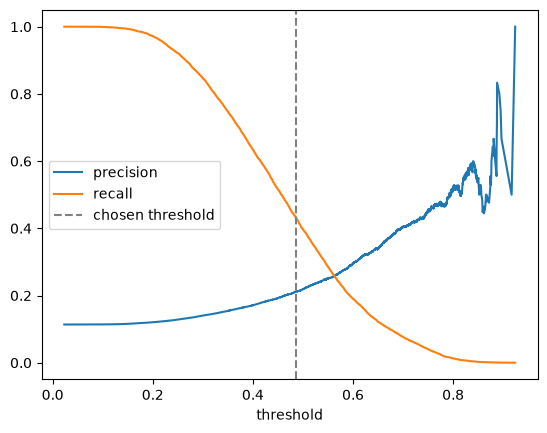

In [15]:
#precision and recall vs threshold
plt.plot(thresholds, precision[:-1], label="precision")
plt.plot(thresholds, recall[:-1], label="recall")
plt.axvline(threshold, ls="--", color="gray", label="chosen threshold")
plt.xlabel("threshold"); plt.legend()
plt.show()

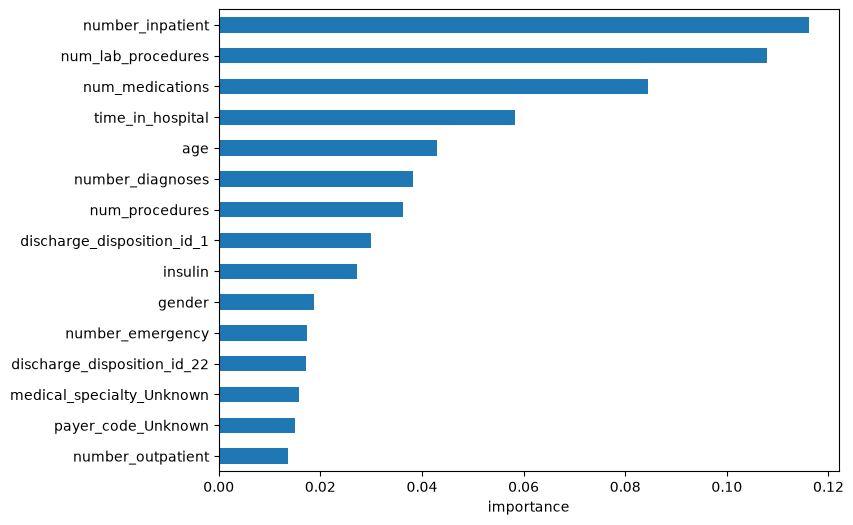

In [16]:
#top 15 important features
importance = pd.Series(best_model["model"].feature_importances_, index=best_model["model"].feature_names_in_)
importance.sort_values().tail(15).plot(kind="barh", figsize=(8, 6))
plt.xlabel("importance")
plt.show()

In [17]:
#saving model, threshold and results
Path("../models").mkdir(exist_ok=True)
joblib.dump(best_model, "../models/final_model.joblib")

selection_results = {
    "final_model": final_name,
    "best_params": best_search.best_params_,
    "cv_pr_auc": round(float(best_search.best_score_), 4),
    "threshold": round(threshold, 4),
    "comparison": comparison.set_index("model")["pr_auc"].to_dict(),
    "tuned_random_forest": round(float(rf_search.best_score_), 4),
    "tuned_xgboost": round(float(xgb_search.best_score_), 4),
    "ensemble": round(float(ensemble_pr), 4),
    "new_features": round(float(fe_pr), 4),
}
json.dump(selection_results, open("../reports/model_selection_results.json", "w"), indent=2)
selection_results

{'final_model': 'Random Forest',
 'best_params': {'model__max_features': 0.3, 'model__min_samples_leaf': 10},
 'cv_pr_auc': 0.2264,
 'threshold': 0.4855,
 'comparison': {'Random Forest': 0.219,
  'Extra Trees': 0.2171,
  'XGBoost': 0.2029,
  'KNN': 0.1749,
  'Decision Tree': 0.1643},
 'tuned_random_forest': 0.2264,
 'tuned_xgboost': 0.2239,
 'ensemble': 0.2271,
 'new_features': 0.2253}